# CARDIOVASCULAR HEART DISEASES PREDICTION
---

### CSE422 Lab Project

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv("heart_data.csv")
df.head()

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
df.tail()

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1
69999,69999,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0


In [ ]:
df.shape

(70000, 14)

## Null Value Checker

In [ ]:
 df.isnull().sum()

,0
index,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        70000 non-null  int64  
 1   id           70000 non-null  int64  
 2   age          70000 non-null  int64  
 3   gender       70000 non-null  int64  
 4   height       70000 non-null  int64  
 5   weight       70000 non-null  float64
 6   ap_hi        70000 non-null  int64  
 7   ap_lo        70000 non-null  int64  
 8   cholesterol  70000 non-null  int64  
 9   gluc         70000 non-null  int64  
 10  smoke        70000 non-null  int64  
 11  alco         70000 non-null  int64  
 12  active       70000 non-null  int64  
 13  cardio       70000 non-null  int64  
dtypes: float64(1), int64(13)
memory usage: 7.5 MB


In [ ]:
sparsity = 0.2
num_elements = df['height'].size
num_nulls = int(sparsity * num_elements)


null_indices = np.random.choice(df['height'].index, num_nulls, replace=False)
df.loc[null_indices, 'height'] = np.nan

In [ ]:
df.head()

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0,18393,2,NaN,62.0,110,80,1,1,0,0,1,0
1,1,1,20228,1,156.0,85.0,140,90,3,1,0,0,1,1
2,2,2,18857,1,165.0,64.0,130,70,3,1,0,0,0,1
3,3,3,17623,2,169.0,82.0,150,100,1,1,0,0,1,1
4,4,4,17474,1,156.0,56.0,100,60,1,1,0,0,0,0


In [ ]:
num_nulls = int(0.05 * df.shape[0])
random_indices = np.random.choice(df.index, num_nulls, replace=False)

df.loc[random_indices, 'age'] = np.nan
df_cleaned = df.dropna()

print("Cleaned DataFrame (rows with NaN removed):")
print(df_cleaned.head())

Cleaned DataFrame (rows with NaN removed):
   index  id      age  gender  height  weight  ap_hi  ap_lo  cholesterol  \
1      1   1  20228.0       1   156.0    85.0    140     90            3   
2      2   2  18857.0       1   165.0    64.0    130     70            3   
3      3   3  17623.0       2   169.0    82.0    150    100            1   
6      6   9  22113.0       1   157.0    93.0    130     80            3   
8      8  13  17668.0       1   158.0    71.0    110     70            1   

   gluc  smoke  alco  active  cardio  
1     1      0     0       1       1  
2     1      0     0       0       1  
3     1      0     0       1       1  
6     1      0     0       1       0  
8     1      0     0       1       0  


In [ ]:
df.head()

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0,18393.0,2,NaN,62.0,110,80,1,1,0,0,1,0
1,1,1,20228.0,1,156.0,85.0,140,90,3,1,0,0,1,1
2,2,2,18857.0,1,165.0,64.0,130,70,3,1,0,0,0,1
3,3,3,17623.0,2,169.0,82.0,150,100,1,1,0,0,1,1
4,4,4,NaN,1,156.0,56.0,100,60,1,1,0,0,0,0


In [ ]:
df.isnull().sum()

,0
index,0
id,0
age,3500
gender,0
height,14000
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0


In [ ]:
df_cleaned = df.dropna()
df['age'] = df['age'].fillna(df['age'].mean())
print(df_cleaned.head())

   index  id      age  gender  height  weight  ap_hi  ap_lo  cholesterol  \
1      1   1  20228.0       1   156.0    85.0    140     90            3   
2      2   2  18857.0       1   165.0    64.0    130     70            3   
3      3   3  17623.0       2   169.0    82.0    150    100            1   
6      6   9  22113.0       1   157.0    93.0    130     80            3   
8      8  13  17668.0       1   158.0    71.0    110     70            1   

   gluc  smoke  alco  active  cardio  
1     1      0     0       1       1  
2     1      0     0       0       1  
3     1      0     0       1       1  
6     1      0     0       1       0  
8     1      0     0       1       0  


In [ ]:
df.dtypes

,0
index,int64
id,int64
age,float64
gender,int64
height,float64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64


In [ ]:
df.isnull().sum()

,0
index,0
id,0
age,0
gender,0
height,14000
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        70000 non-null  int64  
 1   id           70000 non-null  int64  
 2   age          70000 non-null  float64
 3   gender       70000 non-null  int64  
 4   height       56000 non-null  float64
 5   weight       70000 non-null  float64
 6   ap_hi        70000 non-null  int64  
 7   ap_lo        70000 non-null  int64  
 8   cholesterol  70000 non-null  int64  
 9   gluc         70000 non-null  int64  
 10  smoke        70000 non-null  int64  
 11  alco         70000 non-null  int64  
 12  active       70000 non-null  int64  
 13  cardio       70000 non-null  int64  
dtypes: float64(3), int64(11)
memory usage: 7.5 MB


## Correlation

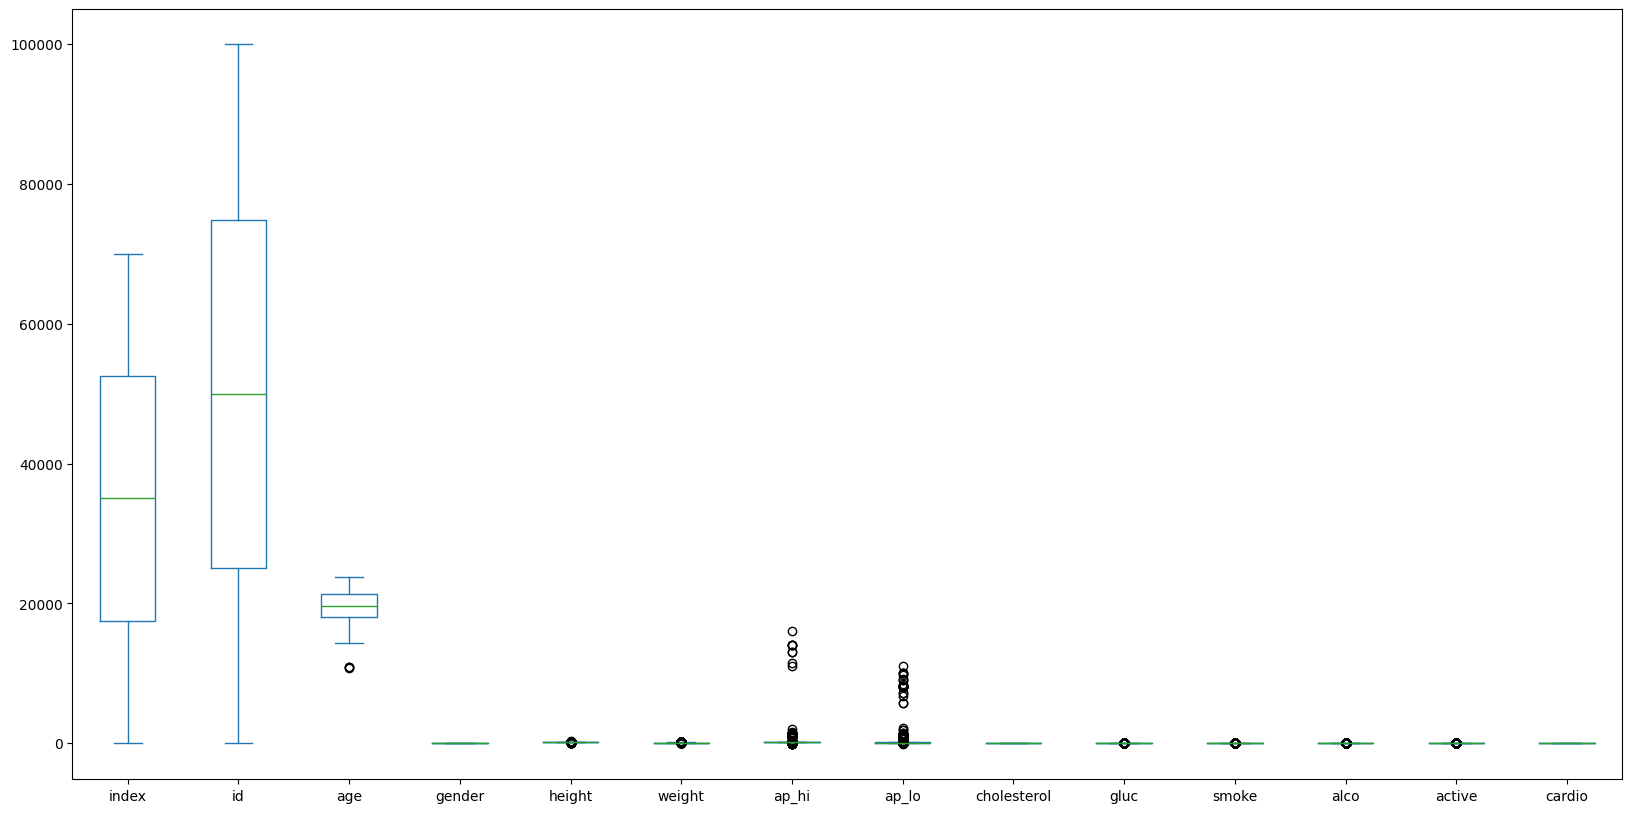

In [ ]:
df.plot(kind='box',figsize=(20,10))
plt.show()

In [ ]:
df_corr = df.corr()
df_corr

,index,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
index,1.000000,0.999999,0.002237,0.003506,-0.005793,-0.001828,0.003359,-0.002533,0.006114,0.002470,-0.003697,0.001214,0.003766,0.003800
id,0.999999,1.000000,0.002239,0.003502,-0.005794,-0.001830,0.003356,-0.002529,0.006106,0.002467,-0.003699,0.001210,0.003755,0.003799
age,0.002237,0.002239,1.000000,-0.021202,-0.076678,0.053663,0.018061,0.017752,0.151435,0.096394,-0.044985,-0.027779,-0.008714,0.233180
gender,0.003506,0.003502,-0.021202,1.000000,0.499001,0.155406,0.006005,0.015254,-0.035821,-0.020491,0.338135,0.170966,0.005866,0.008109
height,-0.005793,-0.005794,-0.076678,0.499001,1.000000,0.292470,0.004242,0.008837,-0.051116,-0.018826,0.188059,0.093999,-0.006817,-0.009596
weight,-0.001828,-0.001830,0.053663,0.155406,0.292470,1.000000,0.030702,0.043710,0.141768,0.106857,0.067780,0.067113,-0.016867,0.181660
ap_hi,0.003359,0.003356,0.018061,0.006005,0.004242,0.030702,1.000000,0.016086,0.023778,0.011841,-0.000922,0.001408,-0.000033,0.054475
ap_lo,-0.002533,-0.002529,0.017752,0.015254,0.008837,0.043710,0.016086,1.000000,0.024019,0.010806,0.005186,0.010601,0.004780,0.065719
cholesterol,0.006114,0.006106,0.151435,-0.035821,-0.051116,0.141768,0.023778,0.024019,1.000000,0.451578,0.010354,0.035760,0.009911,0.221147
gluc,0.002470,0.002467,0.096394,-0.020491,-0.018826,0.106857,0.011841,0.010806,0.451578,1.000000,-0.004756,0.011246,-0.006770,0.089307


# Heatmap

<Axes: >

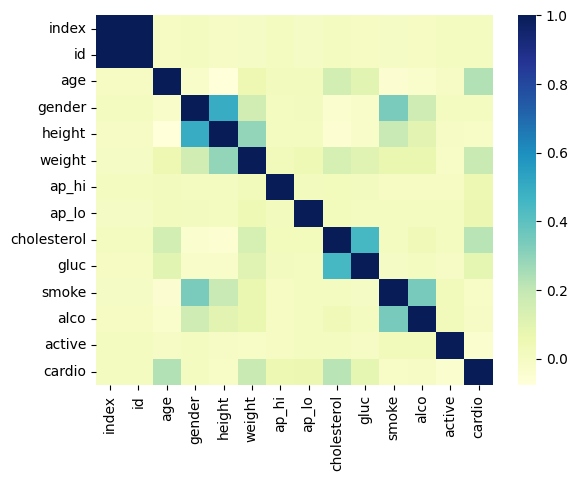

In [ ]:
import seaborn as sns
sns.heatmap(df_corr, cmap = 'YlGnBu')

# Dropin unwanted data Clearing

In [ ]:
df = df.drop(['index', 'id', 'height'], axis = 1)
df.shape

(70000, 11)

In [ ]:
df.head()

,age,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393.000000,2,62.0,110,80,1,1,0,0,1,0
1,20228.000000,1,85.0,140,90,3,1,0,0,1,1
2,18857.000000,1,64.0,130,70,3,1,0,0,0,1
3,17623.000000,2,82.0,150,100,1,1,0,0,1,1
4,19467.206767,1,56.0,100,60,1,1,0,0,0,0


In [ ]:
predict = df['cardio']
df = df.drop(['cardio'], axis = 1)

In [ ]:
predict.head()

,cardio
0,0
1,1
2,1
3,1
4,0


# Feature Scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(df, predict,
                                                    random_state=1)
print(X_train.shape)
print(X_test.shape)

(52500, 10)
(17500, 10)


In [ ]:
scaler = MinMaxScaler()
scaler.fit(X_train)

MinMaxScaler()

In [ ]:
X_train_scaled = scaler.transform(X_train)

In [ ]:
print("per-feature minimum before scaling:\n {}".format(X_train.min(axis=0)))
print("per-feature maximum before scaling:\n {}".format(X_train.max(axis=0)))

per-feature minimum before scaling:
 age            10798.0
gender             1.0
weight            11.0
ap_hi           -150.0
ap_lo            -70.0
cholesterol        1.0
gluc               1.0
smoke              0.0
alco               0.0
active             0.0
dtype: float64
per-feature maximum before scaling:
 age            23690.0
gender             2.0
weight           200.0
ap_hi          16020.0
ap_lo          11000.0
cholesterol        3.0
gluc               3.0
smoke              1.0
alco               1.0
active             1.0
dtype: float64


In [ ]:
print("per-feature minimum after scaling:\n {}".format(
    X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(
    X_train_scaled.max(axis=0)))

per-feature minimum after scaling:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
per-feature maximum after scaling:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.model_selection import train_test_split

# Load dataset
X = df
y = predict

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Gaussian Naive Bayes

Accuracy: 0.5949047619047619
Confusion Matrix:
 [[9104 1357]
 [7150 3389]]
Gausion Naive Bayes Classification Report:
               precision    recall  f1-score   support

           0       0.56      0.87      0.68     10461
           1       0.71      0.32      0.44     10539

    accuracy                           0.59     21000
   macro avg       0.64      0.60      0.56     21000
weighted avg       0.64      0.59      0.56     21000



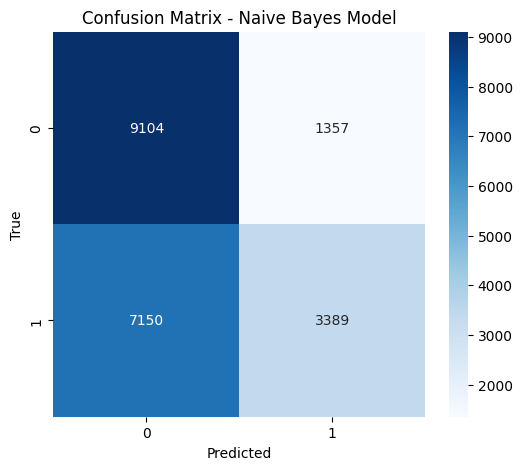

In [ ]:
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Gausion Naive Bayes Classification Report:\n", report)


# Create a heatmap of the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')

# Labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Naive Bayes Model')

# Show the plot
plt.show()

In [ ]:
scaler = MinMaxScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)

y_test_scaled = scaler.transform(y_test)

#train
model.fit(X_train_scaled, y_train)

# scoring on the scaled test set
print("Scaled test set accuracy: {:.2f}".format(
    model.score(X_test_scaled, y_test)))

Scaled test set accuracy: 0.59


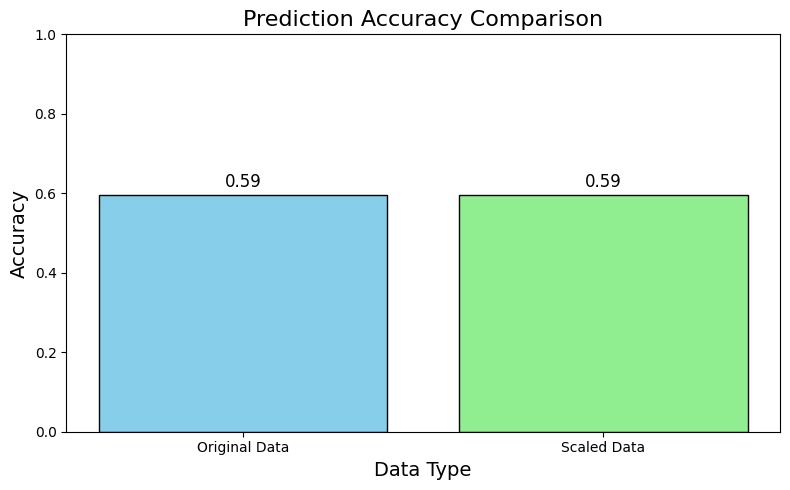

In [ ]:
accuracy_unscaled = accuracy_score(y_test, y_pred)

# Calculate accuracy for scaled data
accuracy_scaled = model.score(X_test_scaled, y_test)

# Define the accuracies for comparison
accuracies = {
    "Original Data": accuracy_unscaled,
    "Scaled Data": accuracy_scaled
}

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=['skyblue', 'lightgreen'], edgecolor='black')

# Add labels and title
plt.xlabel('Data Type', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Prediction Accuracy Comparison', fontsize=16)
plt.ylim(0, 1.0)  # Accuracy ranges between 0 and 1

# Display accuracy values above bars
for i, (key, value) in enumerate(accuracies.items()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha='center', fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()

# **Decision Tree**

Accuracy: 0.6359523809523809
Confusion Matrix:
 [[6640 3821]
 [3824 6715]]
 Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.63      0.63     10461
           1       0.64      0.64      0.64     10539

    accuracy                           0.64     21000
   macro avg       0.64      0.64      0.64     21000
weighted avg       0.64      0.64      0.64     21000



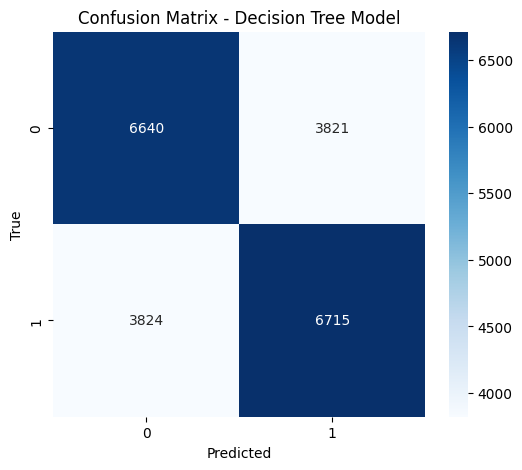

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt


# Train Naive Bayes model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print(" Decision Tree Classification Report:\n", report)


# Create a heatmap of the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')

# Labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Decision Tree Model')

# Show the plot
plt.show()

In [ ]:
scaler = MinMaxScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)

X_test_scaled = scaler.transform(X_test)

#train
model.fit(X_train_scaled, y_train)

# scoring on the scaled test set
print("Scaled test set accuracy: {:.2f}".format(
    model.score(X_test_scaled, y_test)))

Scaled test set accuracy: 0.64


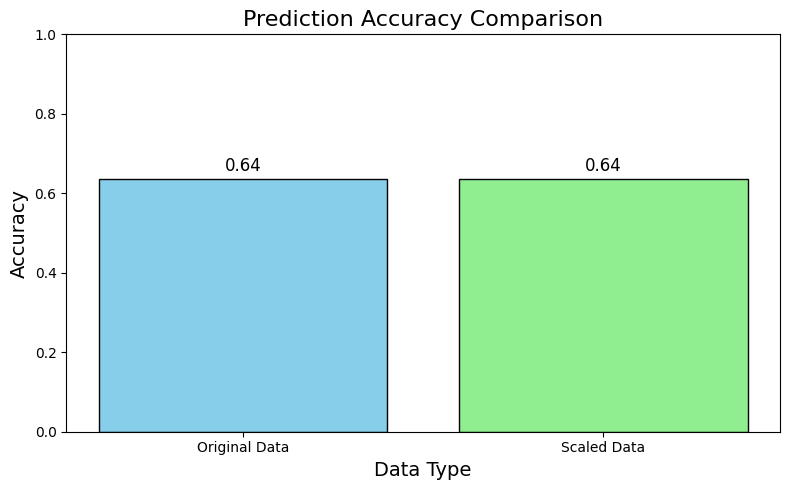

In [ ]:
accuracy_unscaled = accuracy_score(y_test, y_pred)

# Calculate accuracy for scaled data
accuracy_scaled = model.score(X_test_scaled, y_test)

# Define the accuracies for comparison
accuracies = {
    "Original Data": accuracy_unscaled,
    "Scaled Data": accuracy_scaled
}

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=['skyblue', 'lightgreen'], edgecolor='black')

# Add labels and title
plt.xlabel('Data Type', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Prediction Accuracy Comparison', fontsize=16)
plt.ylim(0, 1.0)  # Accuracy ranges between 0 and 1

# Display accuracy values above bars
for i, (key, value) in enumerate(accuracies.items()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha='center', fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()

# Logistic Regression

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.7201428571428572
Confusion Matrix:
 [[7979 2482]
 [3395 7144]]
 Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.76      0.73     10461
           1       0.74      0.68      0.71     10539

    accuracy                           0.72     21000
   macro avg       0.72      0.72      0.72     21000
weighted avg       0.72      0.72      0.72     21000



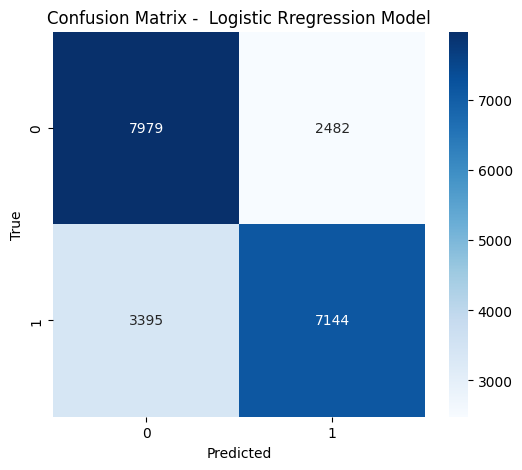

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Train Naive Bayes model
model = LogisticRegression(max_iter = 1000, random_state=4)
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print(" Logistic Regression Classification Report:\n", report)

# Create a heatmap of the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')

# Labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix -  Logistic Rregression Model')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
# Show the plot
plt.show()

In [ ]:
scaler = MinMaxScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)

X_test_scaled = scaler.transform(X_test)

#train
model.fit(X_train_scaled, y_train)

# scoring on the scaled test set
print("Scaled test set accuracy: {:.2f}".format(
    model.score(X_test_scaled, y_test)))

Scaled test set accuracy: 0.65


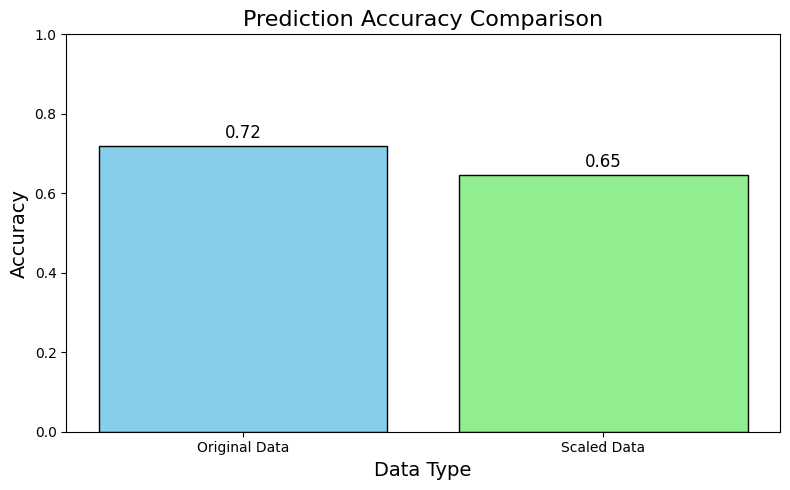

In [ ]:
accuracy_unscaled = accuracy_score(y_test, y_pred)

# Calculate accuracy for scaled data
accuracy_scaled = model.score(X_test_scaled, y_test)

# Define the accuracies for comparison
accuracies = {
    "Original Data": accuracy_unscaled,
    "Scaled Data": accuracy_scaled
}

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=['skyblue', 'lightgreen'], edgecolor='black')

# Add labels and title
plt.xlabel('Data Type', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Prediction Accuracy Comparison', fontsize=16)
plt.ylim(0, 1.0)  # Accuracy ranges between 0 and 1

# Display accuracy values above bars
for i, (key, value) in enumerate(accuracies.items()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha='center', fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
"""# Neural Network (MLP)"""

from sklearn.neural_network import MLPClassifier

# Initialize the MLP
mlp_model = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)

# Train
mlp_model.fit(X_train_scaled, y_train)

# Predict
y_pred_mlp = mlp_model.predict(X_test_scaled)

# Evaluation
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
conf_matrix_mlp = confusion_matrix(y_test, y_pred_mlp)
report_mlp = classification_report(y_test, y_pred_mlp)

print("Neural Network (MLP) Accuracy:", accuracy_mlp)
print("Confusion Matrix:\n", conf_matrix_mlp)
print("Classification Report:\n", report_mlp)

# Confusion matrix heatmap
plt.figure(figsize=(6,5))
sns.heatmap(conf_matrix_mlp, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Neural Network (MLP)")
plt.show()


In [ ]:
"""# K-Means Clustering"""

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Apply KMeans with 2 clusters (since cardio is binary: 0/1)
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_train_scaled)

# Predict cluster labels
cluster_labels = kmeans.predict(X_test_scaled)

# Evaluate clustering quality
ari = adjusted_rand_score(y_test, cluster_labels)  # compares clustering with true labels
print("Adjusted Rand Index (ARI) for KMeans:", ari)

# Show first 20 true vs cluster predictions
comparison = pd.DataFrame({"True Label": y_test[:20].values, "Cluster Label": cluster_labels[:20]})
print(comparison)

# Visualize clustering with 2 features (for example, age & weight)
plt.figure(figsize=(7,5))
plt.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("K-Means Clustering (Test Data)")
plt.show()
